<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM3510-notebooks/master/opim3510_banner.svg" width="100%" alt="OPIM 3510 banner"/>

<a href="https://colab.research.google.com/github/drdave-teaching/OPIM3510-notebooks/blob/master/Module2_TimeSeriesForecasting/2_MovingAverageModel/1_CT_Baselines_and_Moving_Averages.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Baselines, Moving Averages, and How Not to Cheat 🕵️
-----------------------------------------
**Dr. Dave Wanik - University of Connecticut**

# 🔴 Where we left off
Last week we cleaned 11 years of Connecticut electricity demand and found that the **naive forecast** ("tomorrow = today") is off by only about 6% on an average day.

This week we build our first real forecasting models - **moving averages** - and score them honestly. Along the way, you'll learn the three rules every forecaster lives by:

1. **Know your horizon.** How far ahead do you need to see?
2. **Never peek at the future.** Split by time, and only use information you would have had.
3. **Always beat naive.** If a fancy model loses to "same as yesterday," it isn't a model.

## By the end of this notebook, you will be able to:
* Split a time series into **train** and **test** periods (and explain why you can't split randomly)
* Build a moving average forecast with `shift()` and `rolling()`
* Spot **data leakage** - a forecast that secretly uses the answer
* Choose a model setting (the window size) using **only the training data**
* Build a **leaderboard** to compare models with `evaluate()`

# 🔴 Read the clean daily data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# the clean daily file we built last week (also saved in the course repo)
DATA_URL = "https://raw.githubusercontent.com/drdave-teaching/OPIM3510-notebooks/master/data/ct_daily_demand_2011_2021.csv"

# index_col + parse_dates turns the Datetime column into a real datetime index in one step
daily = pd.read_csv(DATA_URL, index_col='Datetime', parse_dates=True)
daily.head()

,Demand_GWh,Temp_avg,Temp_max
Datetime,,,
2011-01-01,77.071,39.90125,50.00
2011-01-02,77.400,42.08750,48.02
2011-01-03,90.982,29.12000,33.98
2011-01-04,93.627,27.98750,39.02
2011-01-05,93.066,27.92000,37.04


In [3]:
daily.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 4018 entries, 2011-01-01 to 2021-12-31
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Demand_GWh  4018 non-null   float64
 1   Temp_avg    4018 non-null   float64
 2   Temp_max    4018 non-null   float64
dtypes: float64(3)
memory usage: 125.6 KB


And our scorecard from last week. (Same function, same sign convention: **error = predicted − actual**, so a positive error means we **over**-forecast.)

In [4]:
def evaluate(actual, predicted, naive=None):
    """Score a forecast. Returns a pandas Series you can stack into a leaderboard.

    actual    : the true values (Series, list, or numpy array)
    predicted : your forecast for the same time steps
    naive     : (optional) a baseline forecast for the same time steps.
                If you give one, you also get "skill vs naive (%)":
                how much smaller your MAE is than the baseline's MAE.
                Positive = you beat the baseline. Negative = the baseline wins.

    Rows where any of the forecasts is missing (NaN) are dropped first,
    so every model is scored on exactly the same time steps.
    """
    # put everything side by side so the rows line up
    scores = pd.DataFrame({"actual": actual, "predicted": predicted})
    if naive is not None:
        scores["naive"] = naive

    # only score time steps where we have every number
    scores = scores.dropna()

    # error = predicted - actual
    error = scores["predicted"] - scores["actual"]

    # the four forecast KPIs
    bias = error.mean()
    mae = error.abs().mean()
    rmse = np.sqrt((error ** 2).mean())
    mape = (error.abs() / scores["actual"].abs()).mean() * 100

    results = {
        "n": len(scores),
        "bias": bias,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
    }

    # how much better than the baseline?
    if naive is not None:
        naive_error = scores["naive"] - scores["actual"]
        naive_mae = naive_error.abs().mean()
        results["skill vs naive (%)"] = (1 - mae / naive_mae) * 100

    return pd.Series(results).round(2)

# 🔴 Rule #1: know your horizon
ISO New England schedules power plants **one day ahead**. So our job is:

> Using everything we know through **today**, forecast **tomorrow's** total demand.

That's a **1-day-ahead** forecast. Every forecast we make this week only uses days *before* the day being forecast.

# 🔴 Rule #2: split by time, not at random
In other classes you may have seen `train_test_split()`, which shuffles rows randomly. **Never do that with a time series.** A random split would put some July 2021 days in training and other July 2021 days in testing - the model would get to "study" days that sit right next to the ones it's tested on. That's peeking at the future.

Instead, we draw a line in time:
* **Train: 2011 - 2020.** We can look at this as much as we want and use it to make choices.
* **Test: 2021.** We pretend it hasn't happened yet. We use it **once**, at the very end, to see how our models really do.

In [5]:
train = daily.loc['2011':'2020']
test = daily.loc['2021']

print('train days:', len(train), ' from', train.index.min().date(), 'to', train.index.max().date())
print('test days: ', len(test), ' from', test.index.min().date(), 'to', test.index.max().date())

train days: 3653  from 2011-01-01 to 2020-12-31
test days:  365  from 2021-01-01 to 2021-12-31


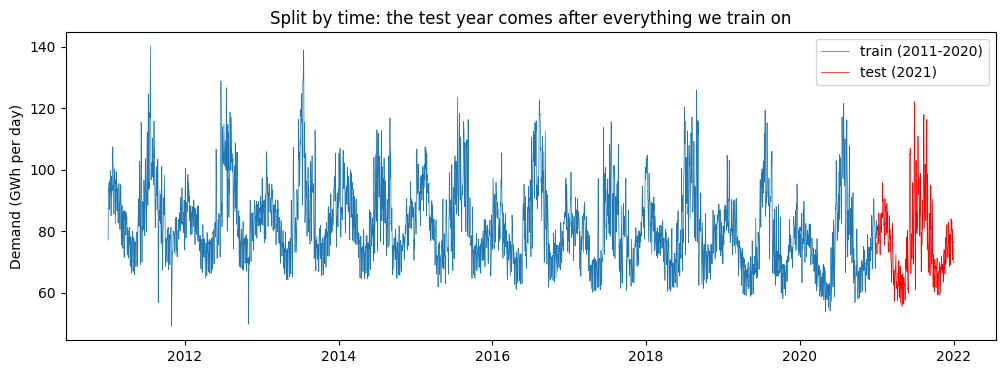

In [6]:
plt.figure(figsize=(12, 4))
plt.plot(train.index, train['Demand_GWh'], linewidth=0.5, label='train (2011-2020)')
plt.plot(test.index, test['Demand_GWh'], linewidth=0.5, color='red', label='test (2021)')
plt.title('Split by time: the test year comes after everything we train on')
plt.ylabel('Demand (GWh per day)')
plt.legend()
plt.show()

# 🔴 The moving average forecast
A **moving average** forecast says: tomorrow will look like the average of the last *n* days.

$$f_t = \frac{1}{n} \sum_{i=1}^{n} d_{t-i}$$

* $f_t$ is the forecast for day $t$
* $d_{t-1}$ is yesterday's demand, $d_{t-2}$ is the day before, and so on
* $n$ is the **window** - how many past days we average

With $n = 3$, the forecast for Thursday is the average of Monday, Tuesday and Wednesday.

In pandas this takes two steps:
1. `shift(1)` slides the column down one row, so each day lines up with **yesterday's** demand.
2. `rolling(3).mean()` averages the last 3 of those shifted values.

In [7]:
# the 3-day moving average forecast (the RIGHT way)
daily['MA_3'] = daily['Demand_GWh'].shift(1).rolling(window=3).mean()

daily[['Demand_GWh', 'MA_3']].head(6)

,Demand_GWh,MA_3
Datetime,,
2011-01-01,77.071,NaN
2011-01-02,77.400,NaN
2011-01-03,90.982,NaN
2011-01-04,93.627,81.817667
2011-01-05,93.066,87.336333
2011-01-06,95.673,92.558333


The first three forecasts are `NaN` - on Jan 1, 2 and 3 we don't have three earlier days to average yet.

**Check it by hand.** The forecast for **Jan 4, 2011** should be the average of Jan 1, 2 and 3:

In [8]:
by_hand = (daily.loc['2011-01-01', 'Demand_GWh'] + daily.loc['2011-01-02', 'Demand_GWh'] + daily.loc['2011-01-03', 'Demand_GWh']) / 3

print('by hand:      ', round(by_hand, 3))
print('from pandas:  ', round(daily.loc['2011-01-04', 'MA_3'], 3))

by hand:       81.818
from pandas:   81.818


They match. ✅ Always check a few rows by hand (or in Excel!) the first time you build a forecast.

# 🔴 Rule #3: never peek at the future
Here's a mistake that is **very** easy to make. What if we forget the `shift(1)`?

In [9]:
# the 3-day moving average WITHOUT the shift
daily['MA_3_cheating'] = daily['Demand_GWh'].rolling(window=3).mean()

daily[['Demand_GWh', 'MA_3', 'MA_3_cheating']].head(6)

,Demand_GWh,MA_3,MA_3_cheating
Datetime,,,
2011-01-01,77.071,NaN,NaN
2011-01-02,77.400,NaN,NaN
2011-01-03,90.982,NaN,81.817667
2011-01-04,93.627,81.817667,87.336333
2011-01-05,93.066,87.336333,92.558333
2011-01-06,95.673,92.558333,94.122000


Let's score both versions on the **training** years, next to the naive forecast.

In [10]:
daily['Naive'] = daily['Demand_GWh'].shift(1)

# re-slice train so it includes the new columns
train = daily.loc['2011':'2020']

honest = evaluate(train['Demand_GWh'], train['MA_3'], naive=train['Naive'])
cheating = evaluate(train['Demand_GWh'], train['MA_3_cheating'], naive=train['Naive'])
naive = evaluate(train['Demand_GWh'], train['Naive'], naive=train['Naive'])

leakage_board = pd.DataFrame({'Naive': naive,
                              'MA_3 (shifted)': honest,
                              'MA_3 (no shift)': cheating})
leakage_board.T

,n,bias,MAE,RMSE,MAPE (%),skill vs naive (%)
Naive,3652.0,-0.0,4.84,6.58,5.89,0.00
MA_3 (shifted),3650.0,0.0,6.24,8.30,7.62,-28.96
MA_3 (no shift),3651.0,-0.0,3.89,5.16,4.75,19.69


**Whoa - the version without the shift *beats* naive!** If you stopped here you'd tell your boss you built a great model. 🎉

You'd be wrong. Look at what goes into the "no shift" forecast for **Jan 4**:

In [11]:
jan = daily.loc['2011-01-01':'2011-01-04', ['Demand_GWh']]
jan

,Demand_GWh
Datetime,
2011-01-01,77.071
2011-01-02,77.400
2011-01-03,90.982
2011-01-04,93.627


In [12]:
print('forecast for Jan 4 (shifted):  average of Jan 1, 2, 3 =', round(daily.loc['2011-01-04', 'MA_3'], 3))
print('forecast for Jan 4 (no shift): average of Jan 2, 3, 4 =', round(daily.loc['2011-01-04', 'MA_3_cheating'], 3))

forecast for Jan 4 (shifted):  average of Jan 1, 2, 3 = 81.818
forecast for Jan 4 (no shift): average of Jan 2, 3, 4 = 87.336


The "no shift" forecast for Jan 4 **includes Jan 4's own demand** - the very number it's supposed to predict! On the morning of Jan 4, nobody knows that number yet. This is called **data leakage**: information from the future leaks into the forecast.

Want proof? Push it to the extreme. A "1-day moving average" with no shift is just... today's demand, used to predict today's demand:

In [13]:
daily['MA_1_cheating'] = daily['Demand_GWh'].rolling(window=1).mean()
train = daily.loc['2011':'2020']

evaluate(train['Demand_GWh'], train['MA_1_cheating'], naive=train['Naive'])

n                     3652.0
bias                     0.0
MAE                      0.0
RMSE                     0.0
MAPE (%)                 0.0
skill vs naive (%)     100.0
dtype: float64

**Zero error.** A perfect forecast. That should set off alarm bells - in the real world, no forecast is perfect.

> ⚠️ **If a forecast looks too good to be true, check for leakage before you celebrate.**

From here on we only use the honest, shifted versions. Let's delete the cheaters so we can't use them by accident.

In [14]:
daily = daily.drop(columns=['MA_3_cheating', 'MA_1_cheating'])

# 🔴 Choosing the window *n* (using only the training data)
Is 3 days the right window? Maybe 7 days (one full week) is better? Let's try several windows and compare their MAE - **on the training years only**. The test year stays locked away.

In [15]:
windows = [1, 2, 3, 5, 7, 14, 28]
train_mae = []

for n in windows:
    # build the moving average forecast for this window
    forecast = daily['Demand_GWh'].shift(1).rolling(window=n).mean()

    # score it on the training years only
    scores = evaluate(daily.loc['2011':'2020', 'Demand_GWh'], forecast.loc['2011':'2020'])
    train_mae.append(scores['MAE'])
    print('window', n, '-> train MAE', scores['MAE'])

window 1 -> train MAE 4.84
window 2 -> train MAE 5.84
window 3 -> train MAE 6.24
window 5 -> train MAE 6.45
window 7 -> train MAE 6.04
window 14 -> train MAE 6.24
window 28 -> train MAE 6.9


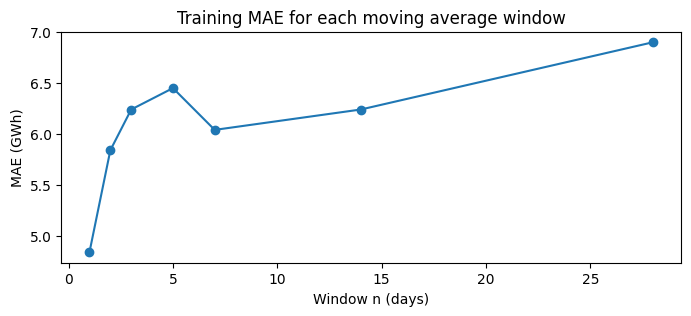

In [16]:
plt.figure(figsize=(8, 3))
plt.plot(windows, train_mae, marker='o')
plt.title('Training MAE for each moving average window')
plt.xlabel('Window n (days)')
plt.ylabel('MAE (GWh)')
plt.show()

**The best window is n = 1** - and a 1-day moving average is just "yesterday's demand." The naive forecast!

Every longer window does *worse*. Why? Remember last week: **weather is sticky**, so yesterday is the best single clue we have. Averaging in older days dilutes that clue with information from days that had different weather. The longer the window, the more the forecast **lags** behind what's happening.

(Notice the little dip at **n = 7**? A 7-day window always holds exactly one Saturday and one Sunday, so the weekend effect averages out. Hold that thought - it's a clue we'll use later in this notebook.)

You can see the lag clearly in July 2021, when a heat wave hit at the end of June:

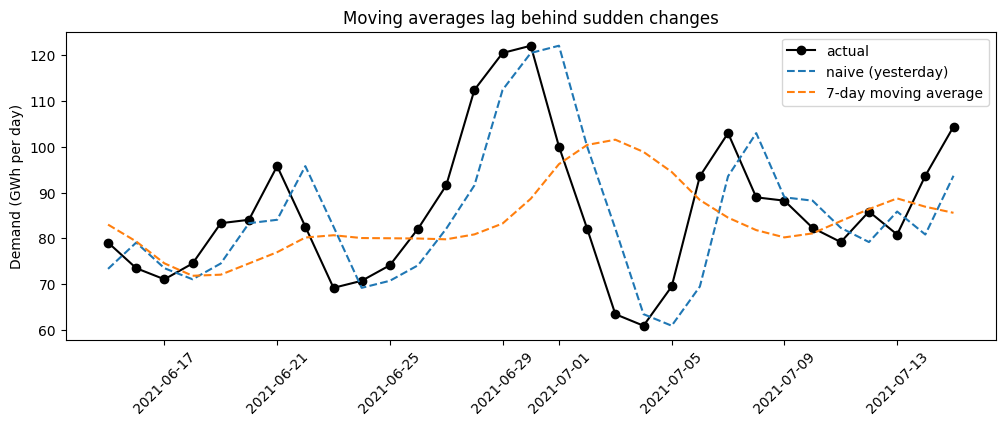

In [17]:
daily['MA_7'] = daily['Demand_GWh'].shift(1).rolling(window=7).mean()

july = daily.loc['2021-06-15':'2021-07-15']

plt.figure(figsize=(12, 4))
plt.plot(july.index, july['Demand_GWh'], marker='o', color='black', label='actual')
plt.plot(july.index, july['Naive'], linestyle='--', label='naive (yesterday)')
plt.plot(july.index, july['MA_7'], linestyle='--', label='7-day moving average')
plt.title('Moving averages lag behind sudden changes')
plt.ylabel('Demand (GWh per day)')
plt.xticks(rotation=45)
plt.legend()
plt.show()

When the heat wave hits, the 7-day average is still remembering last week's mild days, so it **under-forecasts**. When the heat wave breaks, it's still remembering the hot days, so it **over-forecasts**. Naive is late by one day; the 7-day average is late by several.

**This is still a great result.** You just learned something real about this problem: at the daily level, recent history beats long history. That's the kind of insight a forecasting team pays for.

# 🔴 Can we beat naive? A weekday adjustment
Naive has one obvious blind spot. Last week we saw that weekends use about 9% less electricity. So on **Monday**, naive guesses "same as Sunday" - which will usually be too low. On **Saturday**, it guesses "same as Friday" - usually too high.

Let's fix that with a simple adjustment:

> **Forecast = yesterday's demand + (typical demand for today's weekday − typical demand for yesterday's weekday)**

⚠️ **Rule #2 again:** we compute the "typical demand for each weekday" from the **training years only**. If we used 2021 to compute it, we'd be peeking at the test year.

In [18]:
# average demand for each day of the week - TRAINING YEARS ONLY
# dayofweek: 0 = Monday ... 6 = Sunday
weekday_avg = train['Demand_GWh'].groupby(train.index.dayofweek).mean()
weekday_avg.round(1)

Datetime
0    83.5
1    84.6
2    84.7
3    84.2
4    83.2
5    77.0
6    75.6
Name: Demand_GWh, dtype: float64

In [19]:
# which weekday is each day, and which weekday was yesterday?
daily['weekday'] = daily.index.dayofweek
daily['yesterday_weekday'] = daily['weekday'].shift(1)

# look up the typical demand for each one
daily['today_typical'] = daily['weekday'].map(weekday_avg)
daily['yesterday_typical'] = daily['yesterday_weekday'].map(weekday_avg)

# the weekday adjustment
daily['adjustment'] = daily['today_typical'] - daily['yesterday_typical']

# the new forecast
daily['Naive_weekday'] = daily['Naive'] + daily['adjustment']

daily[['Demand_GWh', 'Naive', 'adjustment', 'Naive_weekday']].loc['2021-01-08':'2021-01-12'].round(1)

,Demand_GWh,Naive,adjustment,Naive_weekday
Datetime,,,,
2021-01-08,82.2,81.4,-1.0,80.4
2021-01-09,78.8,82.2,-6.1,76.1
2021-01-10,75.9,78.8,-1.4,77.4
2021-01-11,85.8,75.9,7.8,83.7
2021-01-12,82.8,85.8,1.1,86.9


Read the table: the forecast for **Monday** gets bumped **up** (Sunday was a quiet day), and the forecast for **Saturday** gets pulled **down**. Tuesday through Friday barely change - those weekdays look alike.

# 🔴 The moment of truth: the test year
We made every choice (the window size, the weekday averages) using only 2011-2020. Now - **once** - we unlock 2021 and build the leaderboard.

In [20]:
daily['Seasonal_naive'] = daily['Demand_GWh'].shift(7)

# re-slice test so it includes all the new columns
test = daily.loc['2021']

models = ['Naive', 'Seasonal_naive', 'MA_3', 'MA_7', 'Naive_weekday']

leaderboard = pd.DataFrame()
for model in models:
    leaderboard[model] = evaluate(test['Demand_GWh'], test[model], naive=test['Naive'])

# one row per model, best MAE on top
leaderboard = leaderboard.T.sort_values('MAE')
leaderboard

,n,bias,MAE,RMSE,MAPE (%),skill vs naive (%)
Naive_weekday,365.0,0.02,4.11,5.90,5.23,14.15
Naive,365.0,0.02,4.79,6.68,6.15,0.00
MA_3,365.0,0.04,6.22,8.78,7.97,-29.88
MA_7,365.0,0.06,6.37,9.22,8.14,-33.06
Seasonal_naive,365.0,0.06,8.11,11.97,10.22,-69.55


**We beat naive!** 🏆 The weekday-adjusted naive forecast has the lowest MAE and positive skill: its errors are about 14% smaller than naive's, on a year it never saw while we built it.

And notice the moving averages: on the test year, just like in training, they lose to naive. Our training-data choices held up on new data - that's what an honest test is for.

# 🔴 Where does our best model still miss?
A leaderboard tells you *how much* a model misses. Error plots tell you *when* and *why*.

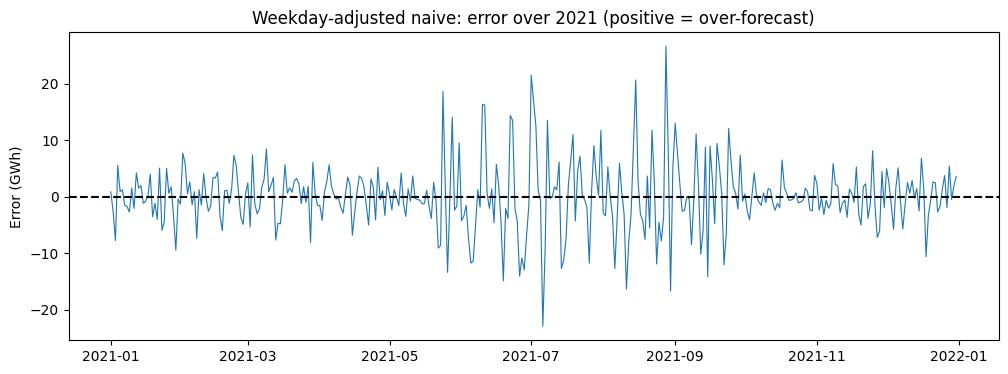

In [21]:
test_error = test['Naive_weekday'] - test['Demand_GWh']

plt.figure(figsize=(12, 4))
plt.plot(test_error.index, test_error, linewidth=0.8)
plt.axhline(0, color='black', linestyle='--')
plt.title('Weekday-adjusted naive: error over 2021 (positive = over-forecast)')
plt.ylabel('Error (GWh)')
plt.show()

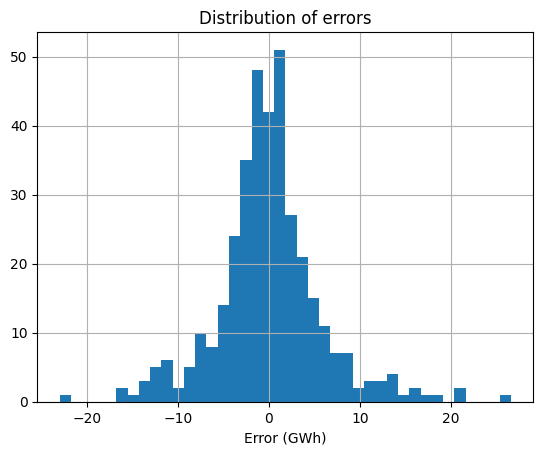

In [22]:
test_error.hist(bins=40)
plt.title('Distribution of errors')
plt.xlabel('Error (GWh)')
plt.show()

The errors are centered near zero (that's the small **bias**), but the biggest misses cluster in the **summer**. Let's look at the worst days:

In [23]:
worst = test_error.abs().nlargest(8).index

worst_days = test.loc[worst, ['Demand_GWh', 'Naive_weekday', 'Temp_avg']].copy()
worst_days['error'] = test_error.loc[worst]
worst_days.round(1)

,Demand_GWh,Naive_weekday,Temp_avg,error
Datetime,,,,
2021-08-28,83.6,110.2,68.7,26.6
2021-07-06,93.5,70.6,75.3,-23.0
2021-07-01,100.0,121.5,73.9,21.5
2021-08-15,81.0,101.6,70.0,20.6
2021-05-24,67.2,85.7,60.1,18.6
2021-07-02,82.1,99.0,64.7,16.9
2021-08-30,98.6,81.9,76.7,-16.7
2021-08-11,108.4,92.0,82.2,-16.4


Most of the worst days are in summer, when temperatures swing quickly from one day to the next: a heat wave arrives and demand jumps, or it breaks and demand drops. A forecast built only on *past demand* can't see that coming.

Look at **July 6** too: the day before was Monday, July 5 - the **observed July 4th holiday**. "Yesterday" was a quiet holiday, so the forecast for a normal Tuesday came in far too low. Holidays fool weekday rules the same way weekends fool naive.

What could? **A weather forecast.** Grid operators feed tomorrow's temperature forecast into their models. Keep that idea in your back pocket.

# 🔴 Summary: the three rules
| Rule | What it looked like today |
|---|---|
| **Know your horizon** | 1 day ahead - every forecast uses only days before it |
| **Never peek at the future** | `shift(1)`; split train/test by time; compute weekday averages on train only |
| **Always beat naive** | Moving averages lost to naive. The weekday adjustment beat it by about 14% |

Next week: **exponential smoothing** - a smarter weighted average that leans hardest on yesterday but still remembers the past.

# 🦾 On your own
1. **Excel twin.** Copy the first 10 days of `daily` into Google Sheets or Excel (`daily['Demand_GWh'].head(10)`). Build the 3-day moving average forecast with a formula and check it matches the `MA_3` column.
2. **Weekday-adjusted moving average.** Apply the same weekday adjustment to `MA_3` instead of `Naive`. Does it beat plain `Naive_weekday` on the **training** years? (Only check the test year after you decide.)
3. **Holidays.** Find the 2021 days where `Naive_weekday` missed by the most in the **winter**. Are any of them holidays? How could you handle holidays?
4. **A different test year.** Redo the leaderboard with train = 2011-2019 and test = 2020. Does the ranking change in the COVID year?
5. **Bias check.** Is `Naive_weekday` biased in summer? Compute the mean error for June-August 2021 only.